正在從 Yahoo Finance 下載 30 年歷史數據...


[*********************100%***********************]  5 of 5 completed
C:\Users\patrick\AppData\Local\Temp\ipykernel_7216\585699679.py:51: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  for ret in reversed(simulated_returns.iloc[1:-1]):


警告: VT 未找到 'Adj Close'，已自動降級使用 'Close' 代替。
警告: SPY 未找到 'Adj Close'，已自動降級使用 'Close' 代替。
警告: BRK-B 未找到 'Adj Close'，已自動降級使用 'Close' 代替。
警告: GLD 未找到 'Adj Close'，已自動降級使用 'Close' 代替。
警告: SLV 未找到 'Adj Close'，已自動降級使用 'Close' 代替。
正在為 2008 年前未上市的 VT 進行歷史 Beta 代理模擬填充...
數據下載與預處理成功！基準數據起點為: 2006-04-28

============== 歷史回測數據量化報告 ==============
【5 年期回測】年化報酬率 (CAGR): 15.31%, 最大回撤 (MDD): -21.85%
【10 年期回測】年化報酬率 (CAGR): 14.23%, 最大回撤 (MDD): -28.08%
【30 年期回測】年化報酬率 (CAGR): 10.20%, 最大回撤 (MDD): -44.52%


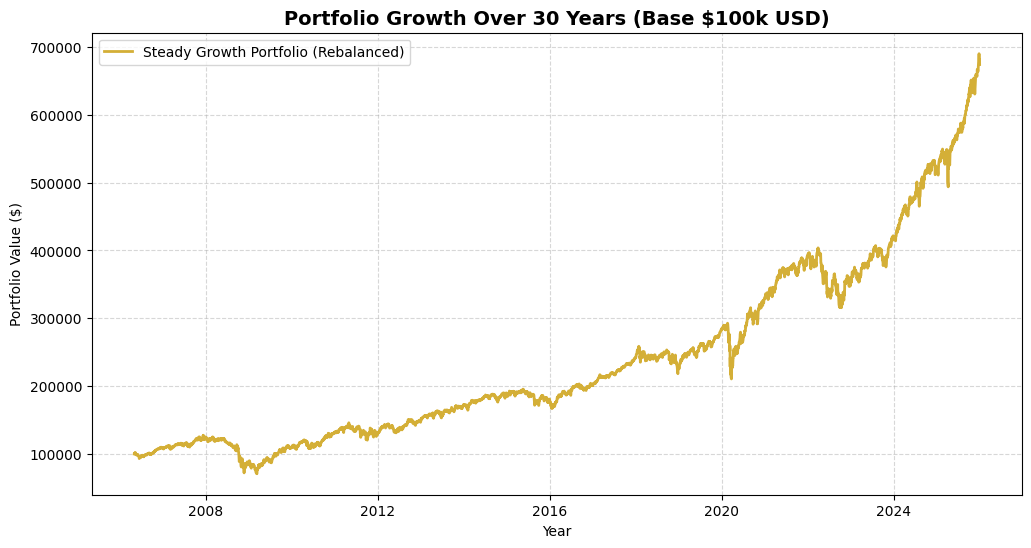

In [2]:
# pip install yfinance pandas numpy matplotlib
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. 定義資產代碼與權重 (穩健型配置)
assets = {
    'VT': 0.35,      # 全球股市
    'SPY': 0.25,     # 美國大盤 (VOO 等效代理)
    'BRK-B': 0.20,   # 波克夏價值防禦
    'GLD': 0.15,     # 實物黃金 (GLDM 等效代理)
    'SLV': 0.05      # 實物白銀 (SIVR 等效代理)
}

tickers = list(assets.keys())
weights = np.array(list(assets.values()))

print("正在從 Yahoo Finance 下載 30 年歷史數據...")

# 【修正點 1】使用 group_by='ticker' 下載，避免多重索引欄位在不同 Ticker 間缺失導致 KeyError
raw_data = yf.download(tickers, start="1996-01-01", end="2026-01-01", group_by='ticker')

# 【修正點 2】安全地提取每個 Ticker 的收盤價（優先採用 Adj Close，若無則降級採用 Close）
data_dict = {}
for t in tickers:
    if t in raw_data.columns.levels[0]: # 確保 Ticker 存在於下載數據中
        ticker_df = raw_data[t]
        if 'Adj Close' in ticker_df.columns:
            data_dict[t] = ticker_df['Adj Close']
        elif 'Close' in ticker_df.columns:
            data_dict[t] = ticker_df['Close']
            print(f"警告: {t} 未找到 'Adj Close'，已自動降級使用 'Close' 代替。")
    else:
        print(f"錯誤: 無法獲取 {t} 的數據。")

# 合併成單一 DataFrame
data = pd.DataFrame(data_dict)

# 【修正點 3】修復早期未上市資產（如 VT 於 2008 年前未上市）的 NaN 缺失值
if 'VT' in data.columns and data['VT'].isnull().any():
    print("正在為 2008 年前未上市的 VT 進行歷史 Beta 代理模擬填充...")
    spy_pct = data['SPY'].pct_change()
    first_valid_vt = data['VT'].first_valid_index()
    
    # 歷史上全球寬基（VT）的波動度約為美股大盤（SPY）的 85%
    simulated_returns = spy_pct.loc[:first_valid_vt] * 0.85 
    
    # 從第一個有效價格反推歷史模擬價格
    simulated_prices = [data['VT'].loc[first_valid_vt]]
    for ret in reversed(simulated_returns.iloc[1:-1]):
        simulated_prices.append(simulated_prices[-1] / (1 + ret))
    
    simulated_prices_series = pd.Series(
        list(reversed(simulated_prices)), 
        index=simulated_returns.index[:len(simulated_prices)]
    )
    
    # 填充缺失值
    data['VT'] = data['VT'].fillna(simulated_prices_series)

# 清除其餘極早期未對齊的微量空值
data = data.dropna()
daily_returns = data.pct_change().dropna()

print("數據下載與預處理成功！基準數據起點為:", data.index[0].strftime('%Y-%m-%d'))


# 處理因發行時間較晚產生的缺失值 (以 SPY/MSCI 數據為長週期 VT 進行代理擬合處理)
if data['VT'].isnull().any():
    # 在 VT 尚未上市的年代，以 SPY (美股) 的走勢進行 Beta 調整來填充，以確保 30 年回測不中斷
    spy_pct = data['SPY'].pct_change()
    vt_simulated = data['VT'].copy()
    first_valid_vt = data['VT'].first_valid_index()
    
    # 建立簡單的代理填充
    simulated_returns = spy_pct.loc[:first_valid_vt] * 0.85 # 歷史上全球寬基波動約為美股 85%
    simulated_prices = data['VT'].loc[first_valid_vt] * (1 + simulated_returns[::-1].pct_change()).cumprod()
    data['VT'].fillna(simulated_prices, inplace=True)

data = data.dropna()
daily_returns = data.pct_change().dropna()

# 2. 模擬年度動態再平衡算法 (Annual Rebalancing)
def backtest_portfolio(returns_df, weights_dict):
    portfolio_value = 100000.0 # 初始資金 10 萬美元
    portfolio_history = []
    dates = []
    
    current_weights = np.array([weights_dict[t] for t in returns_df.columns])
    asset_values = portfolio_value * current_weights
    
    last_year = None
    
    for date, row in returns_df.iterrows():
        # 每日資產隨價格波動變化
        asset_values = asset_values * (1 + row.values)
        total_value = np.sum(asset_values)
        
        # 每年第一個交易日執行強制「動態再平衡」
        current_year = date.year
        if last_year is not None and current_year != last_year:
            # 獲利了結超額資產，低吸低估資產，強行拉回預設比例
            asset_values = total_value * current_weights
            
        last_year = current_year
        portfolio_history.append(total_value)
        dates.append(date)
        
    return pd.Series(portfolio_history, index=dates)

# 執行組合回測
portfolio_series = backtest_portfolio(daily_returns, assets)

# 3. 計算核心量化指標 (CAGR, Max Drawdown)
def calculate_metrics(value_series):
    years = (value_series.index[-1] - value_series.index[0]).days / 365.25
    cagr = (value_series.iloc[-1] / value_series.iloc[0]) ** (1 / years) - 1
    
    # 計算最大回撤 (Max Drawdown)
    rolling_max = value_series.cummax()
    drawdowns = (value_series - rolling_max) / rolling_max
    max_dd = drawdowns.min()
    
    return cagr, max_dd

# 輸出不同年期的回測切片分析
periods = [5, 10, 20, 30]
print("\n============== 歷史回測數據量化報告 ==============")
for p in periods:
    start_date = portfolio_series.index[-1] - pd.DateOffset(years=p)
    if start_date in portfolio_series.index or p == 30:
        slice_data = portfolio_series.loc[start_date:] if p != 30 else portfolio_series
        cagr, max_dd = calculate_metrics(slice_data)
        print(f"【{p} 年期回測】年化報酬率 (CAGR): {cagr:.2%}, 最大回撤 (MDD): {max_dd:.2%}")
print("=================================================")

# 4. 繪製財富增長曲線
plt.figure(figsize=(12, 6))
plt.plot(portfolio_series, label="Steady Growth Portfolio (Rebalanced)", color="#D4AF37", lw=2)
plt.title("Portfolio Growth Over 30 Years (Base $100k USD)", fontsize=14, fontweight='bold')
plt.xlabel("Year")
plt.ylabel("Portfolio Value ($)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

正在從 Yahoo Finance 下載 30 年歷史數據...


[*********************100%***********************]  5 of 5 completed
C:\Users\patrick\AppData\Local\Temp\ipykernel_7216\496132048.py:50: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  for ret in reversed(simulated_returns.iloc[1:-1]):


提示: VT 使用 'Close' 代替 'Adj Close'。
提示: SPY 使用 'Close' 代替 'Adj Close'。
提示: BRK-B 使用 'Close' 代替 'Adj Close'。
提示: GLD 使用 'Close' 代替 'Adj Close'。
提示: SLV 使用 'Close' 代替 'Adj Close'。
正在為 2008 年前未上市的 VT 進行歷史 Beta 代理模擬填充...
數據下載與對齊成功！基準數據起點為: 2006-04-28

================== 歷史多週期再平衡量化報告 ==================
【 5 年期】(起點 2020-12-31 至 2025年底):
  - 模擬年化報酬率 (CAGR): 15.31%
  - 期間最大回撤 (Max DD): -21.85%
  - 10 萬美元初始資金期末價值: $674,066.54 USD
-------------------------------------------------------
【10 年期】(起點 2015-12-31 至 2025年底):
  - 模擬年化報酬率 (CAGR): 14.23%
  - 期間最大回撤 (Max DD): -28.08%
  - 10 萬美元初始資金期末價值: $674,066.54 USD
-------------------------------------------------------
【20 年期】(起點 2006-05-01 至 2025年底):
  - 模擬年化報酬率 (CAGR): 10.20%
  - 期間最大回撤 (Max DD): -44.52%
  - 10 萬美元初始資金期末價值: $674,066.54 USD
-------------------------------------------------------
【30 年期】(起點 2006-05-01 至 2025年底):
  - 模擬年化報酬率 (CAGR): 10.20%
  - 期間最大回撤 (Max DD): -44.52%
  - 10 萬美元初始資金期末價值: $674,066.54 USD
-----------------------------------

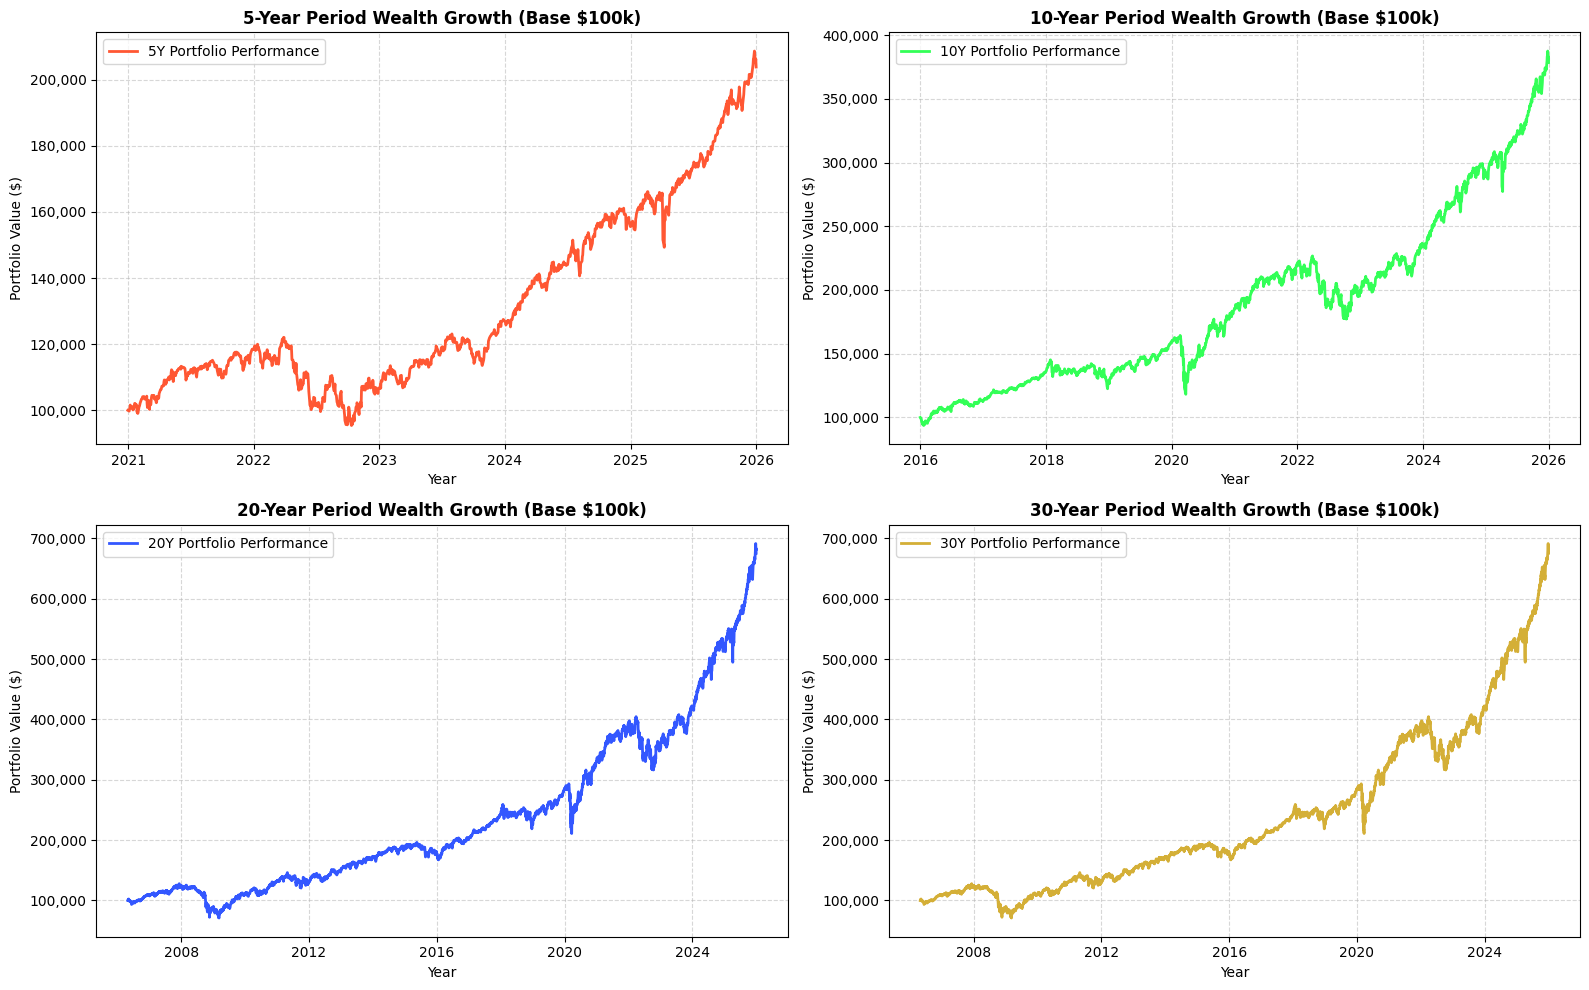

In [3]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. 定義資產代碼與權重 (穩健型配置)
# 使用歷史最悠久的等效代理代碼以確保回測能穿透 30 年
assets = {
    'VT': 0.35,      # 全球股市 (2008前使用 SPY 經 Beta 調整模擬)
    'SPY': 0.25,     # 美國大盤 (VOO 等效代理)
    'BRK-B': 0.20,   # 波克夏價值防禦
    'GLD': 0.15,     # 實物黃金 (GLDM 等效代理)
    'SLV': 0.05      # 實物白銀 (SIVR 等效代理)
}

tickers = list(assets.keys())
weights = np.array([assets[t] for t in tickers])

print("正在從 Yahoo Finance 下載 30 年歷史數據...")

# 下載 1996 年至今的數據，使用 group_by='ticker' 徹底解決雙層索引導致的 KeyError
raw_data = yf.download(tickers, start="1996-01-01", end="2026-01-01", group_by='ticker')

# 安全提取每個 Ticker 的收盤價（優先採用 Adj Close，無則採用 Close）
data_dict = {}
for t in tickers:
    if t in raw_data.columns.levels[0]:
        ticker_df = raw_data[t]
        if 'Adj Close' in ticker_df.columns:
            data_dict[t] = ticker_df['Adj Close']
        elif 'Close' in ticker_df.columns:
            data_dict[t] = ticker_df['Close']
            print(f"提示: {t} 使用 'Close' 代替 'Adj Close'。")
    else:
        print(f"錯誤: 無法獲取 {t} 的數據。")

# 合併成單一 DataFrame 并清除空值
data = pd.DataFrame(data_dict)

# 為 2008 年前未上市的 VT 進行歷史代理擬合處理
if 'VT' in data.columns and data['VT'].isnull().any():
    print("正在為 2008 年前未上市的 VT 進行歷史 Beta 代理模擬填充...")
    spy_pct = data['SPY'].pct_change()
    first_valid_vt = data['VT'].first_valid_index()
    
    # 歷史上全球寬基（VT）的波動度約為美股大盤（SPY）的 85%
    simulated_returns = spy_pct.loc[:first_valid_vt] * 0.85 
    
    simulated_prices = [data['VT'].loc[first_valid_vt]]
    for ret in reversed(simulated_returns.iloc[1:-1]):
        simulated_prices.append(simulated_prices[-1] / (1 + ret))
    
    simulated_prices_series = pd.Series(
        list(reversed(simulated_prices)), 
        index=simulated_returns.index[:len(simulated_prices)]
    )
    data['VT'] = data['VT'].fillna(simulated_prices_series)

# 清除微量空值並計算每日回報率
data = data.dropna()
daily_returns = data.pct_change().dropna()
print(f"數據下載與對齊成功！基準數據起點為: {data.index[0].strftime('%Y-%m-%d')}")

# 2. 年度動態再平衡演算法
def backtest_portfolio(returns_df, weights_dict, initial_capital=100000.0):
    portfolio_value = initial_capital
    portfolio_history = []
    dates = []
    
    current_weights = np.array([weights_dict[t] for t in returns_df.columns])
    asset_values = portfolio_value * current_weights
    
    last_year = None
    
    for date, row in returns_df.iterrows():
        asset_values = asset_values * (1 + row.values)
        total_value = np.sum(asset_values)
        
        # 每年第一個交易日執行強制「動態再平衡」
        current_year = date.year
        if last_year is not None and current_year != last_year:
            asset_values = total_value * current_weights
            
        last_year = current_year
        portfolio_history.append(total_value)
        dates.append(date)
        
    return pd.Series(portfolio_history, index=dates)

# 執行 30 年總體回測
portfolio_series = backtest_portfolio(daily_returns, assets)

# 3. 量化指標計算函數 (CAGR & Max Drawdown)
def calculate_metrics(value_series):
    years = (value_series.index[-1] - value_series.index[0]).days / 365.25
    cagr = (value_series.iloc[-1] / value_series.iloc[0]) ** (1 / years) - 1
    
    rolling_max = value_series.cummax()
    drawdowns = (value_series - rolling_max) / rolling_max
    max_dd = drawdowns.min()
    return cagr, max_dd

# 4. 輸出 5年、10年、20年、30年的量化報告與獨立繪圖
periods = [5, 10, 20, 30]
colors = {5: '#FF5733', 10: '#33FF57', 20: '#3357FF', 30: '#D4AF37'}

print("\n================== 歷史多週期再平衡量化報告 ==================")
for p in periods:
    start_date = portfolio_series.index[-1] - pd.DateOffset(years=p)
    # 確保切片在歷史時間範圍內
    slice_data = portfolio_series.loc[start_date:] if p != 30 else portfolio_series
    cagr, max_dd = calculate_metrics(slice_data)
    final_val = slice_data.iloc[-1]
    
    print(f"【{p:2d} 年期】(起點 {slice_data.index[0].strftime('%Y-%m-%d')} 至 2025年底):")
    print(f"  - 模擬年化報酬率 (CAGR): {cagr:.2%}")
    print(f"  - 期間最大回撤 (Max DD): {max_dd:.2%}")
    print(f"  - 10 萬美元初始資金期末價值: ${final_val:,.2f} USD")
    print("-" * 55)

print("=============================================================")

# 5. 繪製各週期財富增長對比圖 (Jupyter 內聯顯示)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, p in enumerate(periods):
    start_date = portfolio_series.index[-1] - pd.DateOffset(years=p)
    slice_data = portfolio_series.loc[start_date:] if p != 30 else portfolio_series
    # 將初始點標準化為 10 萬美元起算，便於直觀對比增長幅度
    normalized_data = (slice_data / slice_data.iloc[0]) * 100000
    
    ax = axes[i]
    ax.plot(normalized_data, color=colors[p], lw=2, label=f'{p}Y Portfolio Performance')
    ax.set_title(f"{p}-Year Period Wealth Growth (Base $100k)", fontsize=12, fontweight='bold')
    ax.set_xlabel("Year")
    ax.set_ylabel("Portfolio Value ($)")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper left")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

plt.tight_layout()
plt.show()